# Fairness Under Prediction Error in Predict-Then-Optimize

**Author:** Hilda Adwubi Osei

## Research question
In a predict-then-optimize pipeline, if a fairness constraint (demographic parity) is enforced using predicted outcomes ŷ, does it still hold when checked against the true outcomes y? How does the gap between the two grow with prediction error?

## Why this matters
Fairness constraints in deployed systems are almost always enforced on *predictions*, because true outcomes aren't known at decision time, that is the defining feature of predict-then-optimize. If enforcing parity on ŷ doesn't guarantee parity on y, a fairness audit that only checks "we enforced demographic parity" can be misleading. The size of the gap should depend on how good the predictor is, this notebook tries to show that relationship empirically, and later to bound it theoretically.

## What this constraint is, precisely
We study a resource-allocation decision: each person i gets an allocation z_i ∈ [0,1], with a total budget constraint. The fairness constraint enforces equal **per-capita benefit** across two groups, the average value received by group 1 equals the average value received by group 0, where "value" is a vector v that is either ŷ (used to enforce the constraint, since that's all we have at decision time) or y (used afterward, to check whether the constraint still holds in reality).

## Plan
1. Synthetic data with controllable prediction error (σ); solve the constrained allocation with CVXPY; compare the fairness gap measured on ŷ vs measured on y as σ varies.
2. Document the empirical pattern.
3. Derive a bound relating the true-outcome gap to prediction error and sample size.
4. Repeat the pipeline on real data using folktables (US Census-derived benchmark).

## Log of findings
(Each step below contains, what we ran, what we found, and what it means.)

### [date] — Data generation check
Confirmed `make_data()` produces two groups with different true-outcome means (group 1 lower, by design) and that `y_hat` tracks `y_true` with noise scaled by σ, collapsing to `y_true` exactly at σ=0.

In [1]:
import numpy as np
import pandas as pd
import cvxpy as cp
import matplotlib.pyplot as plt

In [2]:
def make_data(n=2000, p_minority=0.3, mu=(2.0, 1.4), sd=0.5, sigma=0.0, seed=0):
    """
    n           : number of people in the dataset
    p_minority  : fraction of people in group 1 (the minority group)
    mu          : (mean outcome for group 0, mean outcome for group 1)
    sd          : how spread out true outcomes are within a group
    sigma       : prediction error size. sigma=0 means perfect predictions.
    seed        : fixes the randomness so results are reproducible
    """
    rng = np.random.default_rng(seed)

    a = rng.binomial(1, p_minority, size=n)      
    y = rng.normal(np.asarray(mu)[a], sd)        
    y_hat = y + sigma * rng.normal(size=n)       

    return a, y, y_hat

In [3]:
a, y, y_hat = make_data(n=10, sigma=0.5, seed=0)
pd.DataFrame({"group": a, "y_true": y, "y_pred": y_hat})

,group,y_true,y_pred
0,0,1.688363,1.624095
1,0,2.020663,2.703895
2,0,0.837485,0.504887
3,0,1.890604,2.066359
4,1,0.777045,1.228780
5,1,1.033866,1.080872
6,0,1.727871,1.356121
7,1,1.241850,0.780987
8,0,2.205815,1.976952
9,1,1.921257,2.031354


## Related work (stub, expand before writing the preprint)

- **E2EFO / Fair Decision-Focused Learning** (2026): defines "decision regret" as the gap between a fairness objective evaluated on a prediction-based decision vs. the true-outcome decision. This is the same *quantity* we study, but their contribution is a training method to shrink it, not a closed-form bound in terms of prediction error. Need to read in full and cite precisely once we draft the paper.

- **"Uncertainty and the Social Planner's Problem"** (Brown): bounds how sample size distorts fairness-objective estimates. Close to our n-dependence, but their uncertainty source is few samples per group, not predictor error per sample. Different mechanism, same flavor.

- **Decision-centric fairness** (2025): argues fairness should be measured only in the decision-relevant region of the score distribution, not globally. Different question (where to enforce), not how error propagates once enforced.

**Our angle, stated plainly:** none of these derive an explicit bound of the form |true-outcome gap| ≤ f(σ, n) for demographic-parity-constrained allocation, built from LP sensitivity/duality and checked empirically first. That empirical-first → derive → validate sequencing is also a point of difference in approach, not just content.

In [4]:
def gap_vector(v, a):
    """
    For each person, returns the coefficient that multiplies their z_i
    in the gap formula: +v_i/n1 if they're in group 1, -v_i/n0 if group 0.
    Dotting this vector with z gives the gap directly.
    """
    n1 = (a == 1).sum()
    n0 = (a == 0).sum()
    return np.where(a == 1, v / n1, -v / n0)

def util_gap(z, v, a):
    """The per-capita benefit gap (group 1 minus group 0), using values v."""
    return gap_vector(v, a) @ z

In [5]:
def solve_allocation(y_hat, a, budget_frac=0.3, eps=None):
    """
    Decide how much of a limited budget each person gets (z_i in [0,1]),
    to maximize total predicted benefit, subject to:
      - a budget constraint (only budget_frac of the population's worth
        of resource can be given out)
      - optionally, a fairness constraint: the predicted gap must be
        within [-eps, eps]

    eps=None means no fairness constraint (unconstrained baseline).
    eps=0.0 means enforce exact parity (on y_hat).
    """
    n = len(y_hat)
    z = cp.Variable(n)

    constraints = [z >= 0, z <= 1, cp.sum(z) <= budget_frac * n]

    if eps is not None:
        predicted_gap = gap_vector(y_hat, a) @ z
        constraints += [predicted_gap <= eps, predicted_gap >= -eps]

    objective = cp.Maximize(y_hat @ z)
    problem = cp.Problem(objective, constraints)
    problem.solve()

    return z.value

In [6]:
a, y, y_hat = make_data(n=2000, sigma=0.0, seed=0)

z_unconstrained = solve_allocation(y_hat, a, eps=None)
z_fair = solve_allocation(y_hat, a, eps=0.0)

print("Unconstrained — gap on y_hat:", util_gap(z_unconstrained, y_hat, a))
print("Unconstrained — gap on y    :", util_gap(z_unconstrained, y, a))
print("Fair           — gap on y_hat:", util_gap(z_fair, y_hat, a))
print("Fair           — gap on y    :", util_gap(z_fair, y, a))

Unconstrained — gap on y_hat: -0.7997476646416242
Unconstrained — gap on y    : -0.7997476646416242
Fair           — gap on y_hat: -5.937125791000142e-13
Fair           — gap on y    : -5.937125791000142e-13


In [7]:
a, y, y_hat = make_data(n=2000, sigma=1.0, seed=0)

z_fair = solve_allocation(y_hat, a, eps=0.0)

print("Fair solution — gap on y_hat:", util_gap(z_fair, y_hat, a))
print("Fair solution — gap on y    :", util_gap(z_fair, y, a))

Fair solution — gap on y_hat: -2.518200925560876e-12
Fair solution — gap on y    : -0.07904653228851102


### First evidence of the gap
With sigma=0, enforcing demographic parity on y_hat gives a gap on y_hat
of ~0 and an identical gap on y (expected, since y_hat = y exactly).

With sigma=1.0 (n=2000, seed=0), the gap on y_hat remains ~0 (the
constraint held, as designed) but the gap on y is -0.079, noticeably
nonzero, though far smaller in magnitude than the unconstrained gap of
-0.80. This is the first direct evidence that enforcing demographic
parity on predictions does not guarantee it holds on true outcomes,
and that prediction error is the mechanism: the optimizer selects
individuals partly based on noise it cannot distinguish from signal,
and that noise is not symmetric with respect to the fairness constraint
once the true values are revealed.

Open question for the sweep: does this gap grow roughly linearly in
sigma, like sqrt(sigma), or something else? And does it shrink as n
grows (more people regularizing out the noise) or stay roughly fixed?

In [8]:
def run_sweep(sigmas, n=2000, n_seeds=20, budget_frac=0.3):
    """
    For each sigma value, run n_seeds independent trials (different
    random data each time) and record the true-outcome gap.
    Returns a long-format DataFrame: one row per (sigma, seed).
    """
    records = []
    for sigma in sigmas:
        for seed in range(n_seeds):
            a, y, y_hat = make_data(n=n, sigma=sigma, seed=seed)
            z_fair = solve_allocation(y_hat, a, budget_frac=budget_frac, eps=0.0)
            true_gap = util_gap(z_fair, y, a)
            records.append({"sigma": sigma, "seed": seed, "true_gap": true_gap})
    return pd.DataFrame(records)

In [9]:
sigmas = np.linspace(0, 2, 11)  
results = run_sweep(sigmas, n=2000, n_seeds=20)
results.groupby("sigma")["true_gap"].agg(["mean", "std"])

,mean,std
sigma,,
0.0,-1.409178e-12,1.521984e-12
0.2,-5.636047e-03,4.920027e-03
0.4,-1.467912e-02,1.033778e-02
0.6,-2.519253e-02,1.273074e-02
0.8,-3.379019e-02,1.553580e-02
1.0,-4.341551e-02,1.731813e-02
1.2,-5.128312e-02,1.909901e-02
1.4,-5.826440e-02,2.062967e-02
1.6,-6.523414e-02,2.212843e-02


### Sweep over sigma (n=2000, 20 seeds per sigma)
The mean true-outcome gap grows monotonically with sigma but *concavely*, the per-step increase shrinks as sigma increases (first differences, drop from ~0.009 to ~0.006 as sigma goes from ~0.3 to ~2.0). This
suggests the gap is saturating toward some ceiling, not growing without bound, which is structurally expected: z is bounded in [0,1] and budget-constrained, so the gap itself is bounded.

Also notable: the std across seeds grows with sigma too (from ~0.005 at sigma=0.2 to ~0.026 at sigma=2.0), more prediction noise also means more run-to-run variability in the resulting unfairness, not just a bigger average.

Open question for step 3: what's the right functional form to fit? Candidates to test: c*sigma/(1+sigma), c*(1-exp(-sigma/tau)). Also need to check how n affects this, does a bigger n shrink the gap (more data regularizing out individual noise) or just shrink its variance?

In [10]:
def run_n_sweep(ns, sigmas, n_seeds=20, budget_frac=0.3):
    
    records = []
    for n in ns:
        for sigma in sigmas:
            for seed in range(n_seeds):
                a, y, y_hat = make_data(n=n, sigma=sigma, seed=seed)
                z_fair = solve_allocation(y_hat, a, budget_frac=budget_frac, eps=0.0)
                true_gap = util_gap(z_fair, y, a)
                records.append({"n": n, "sigma": sigma, "seed": seed, "true_gap": true_gap})
    return pd.DataFrame(records)

In [11]:
ns = [500, 1000, 2000, 4000, 8000]
sigmas_for_n_sweep = [0.5, 1.0, 1.5]

n_results = run_n_sweep(ns, sigmas_for_n_sweep, n_seeds=20)
n_results.groupby(["sigma", "n"])["true_gap"].agg(["mean", "std"])

mean       std
sigma n                       
0.5   500  -0.004206  0.026716
      1000 -0.014540  0.015529
      2000 -0.020351  0.011512
      4000 -0.018049  0.008924
      8000 -0.015426  0.006151
1.0   500  -0.021957  0.045499
      1000 -0.040359  0.029239
      2000 -0.043416  0.017318
      4000 -0.038551  0.016759
      8000 -0.037768  0.008754
1.5   500  -0.036808  0.055592
      1000 -0.056555  0.036431
      2000 -0.061084  0.022071
      4000 -0.055534  0.021313
      8000 -0.054738  0.012508

In [12]:
ns = [500, 1000, 2000, 4000, 8000]
sigmas_for_n_sweep = [0.5, 1.0, 1.5]

n_results_more = run_n_sweep(ns, sigmas_for_n_sweep, n_seeds=100)  # was 20
summary = n_results_more.groupby(["sigma", "n"])["true_gap"].agg(["mean", "std", "count"])
summary["se"] = summary["std"] / np.sqrt(summary["count"])
summary

mean       std  count        se
sigma n                                        
0.5   500  -0.013130  0.024090    100  0.002409
      1000 -0.015224  0.018383    100  0.001838
      2000 -0.015378  0.012019    100  0.001202
      4000 -0.015943  0.009257    100  0.000926
      8000 -0.015364  0.006139    100  0.000614
1.0   500  -0.033314  0.038083    100  0.003808
      1000 -0.034624  0.030883    100  0.003088
      2000 -0.036783  0.017160    100  0.001716
      4000 -0.036113  0.014790    100  0.001479
      8000 -0.035545  0.009219    100  0.000922
1.5   500  -0.047068  0.049350    100  0.004935
      1000 -0.049854  0.038807    100  0.003881
      2000 -0.053174  0.022202    100  0.002220
      4000 -0.052103  0.019446    100  0.001945
      8000 -0.051452  0.011862    100  0.001186

### n-sweep, corrected with 100 seeds
The initial 20-seed n-sweep suggested the gap shrinks as n grows. With 100 seeds (smaller SE), this does not hold up: the *mean* true-outcome gap is roughly flat across n in [500, 8000] at each fixed sigma. What does shrink with n is the *std* of the gap across seeds, by a factor consistent with std ~ 1/sqrt(n) (e.g. at sigma=0.5: std drops from
0.024 at n=500 to 0.0061 at n=8000, a ~3.95x drop for a 16x increase in n, matching sqrt(16)=4).

Interpretation: the true-outcome fairness gap has two components, a systematic bias (driven by sigma, apparently n-invariant) and sampling noise around it (shrinking like 1/sqrt(n), standard CLT behavior). The bias not vanishing with n suggests an "optimizer's curse"-type mechanism: the optimizer selects individuals partly based on favorable
noise, and that selection bias is structural, not an averaging effect, so it persists regardless of sample size. This differs from the sample-complexity fairness bounds in related work (e.g. the Brown paper), whose bounds vanish with n because their noise source is estimating group means from finite samples, not per-individual prediction error feeding a selection mechanism.

Implication for step 3: the bound we derive should be a function of sigma only (not n) for the bias term, plus a separate O(1/sqrt(n)) term for the estimation noise around it.

In [13]:
sigmas_fine = np.linspace(0, 3, 16)   
n_fixed = 4000
n_seeds_fine = 100

fine_results = run_sweep(sigmas_fine, n=n_fixed, n_seeds=n_seeds_fine)
fine_summary = fine_results.groupby("sigma")["true_gap"].agg(["mean", "std", "count"])
fine_summary["se"] = fine_summary["std"] / np.sqrt(fine_summary["count"])
fine_summary

,mean,std,count,se
sigma,,,,
0.0,-7.019032e-13,8.480348e-13,100,8.480348e-14
0.2,-3.747862e-03,4.408118e-03,100,4.408118e-04
0.4,-1.193470e-02,8.079492e-03,100,8.079492e-04
0.6,-2.024342e-02,1.068321e-02,100,1.068321e-03
0.8,-2.862584e-02,1.219280e-02,100,1.219280e-03
1.0,-3.611256e-02,1.479013e-02,100,1.479013e-03
1.2,-4.312365e-02,1.717839e-02,100,1.717839e-03
1.4,-4.938485e-02,1.875216e-02,100,1.875216e-03
1.6,-5.509845e-02,2.036405e-02,100,2.036405e-03


In [14]:
sigmas_extended = np.array([0, 1, 2, 3, 4, 6, 8, 10, 14, 20])
n_seeds_extended = 60   

extended_results = run_sweep(sigmas_extended, n=4000, n_seeds=n_seeds_extended)
extended_summary = extended_results.groupby("sigma")["true_gap"].agg(["mean", "std", "count"])
extended_summary["se"] = extended_summary["std"] / np.sqrt(extended_summary["count"])
extended_summary

,mean,std,count,se
sigma,,,,
0,-6.360464e-13,8.211557e-13,60,1.060107e-13
1,-3.802038e-02,1.506960e-02,60,1.945477e-03
2,-6.595667e-02,2.391057e-02,60,3.086841e-03
3,-8.557860e-02,2.826006e-02,60,3.648359e-03
4,-9.944147e-02,3.206535e-02,60,4.139618e-03
6,-1.174100e-01,3.590722e-02,60,4.635603e-03
8,-1.286909e-01,3.907021e-02,60,5.043942e-03
10,-1.365429e-01,4.119593e-02,60,5.318372e-03
14,-1.466995e-01,4.354549e-02,60,5.621699e-03


### Extended sigma range (0 to 20), functional form identified
Extending the sweep to sigma=20 (n=4000, 60 seeds at large sigma, 100
seeds at small sigma) rules out linear growth decisively (RMSE 0.050
vs 0.003 for the best candidate). The data is well fit by exponential
saturation:

    |gap(sigma)| ~ c * (1 - exp(-sigma/tau)),  c ~ 0.155, tau ~ 3.95

This fit is trustworthy (unlike the earlier short-range attempt) because
tau now falls inside the tested range rather than far outside it, and
the predicted ceiling (0.155) matches the observed value at sigma=20
(0.1548) almost exactly.

Physical interpretation: small-sigma behavior is linear (~ (c/tau)*sigma),
consistent with a first-order sensitivity/perturbation effect. Large-sigma
behavior saturates to a budget-and-outcome-distribution-determined ceiling,
consistent with the optimizer effectively ignoring uninformative predictions
and the resulting unfairness being capped by the bounded decision variable.

This is now the target shape for step 3: derive a bound whose small-sigma
behavior is linear and whose large-sigma behavior saturates, rather than
chasing a simple linear or sqrt bound.

In [15]:
from scipy.optimize import curve_fit

combined_sigma = pd.concat([
    fine_summary.reset_index()["sigma"],
    extended_summary.reset_index()["sigma"]
]).values

combined_gap = np.abs(pd.concat([
    fine_summary.reset_index()["mean"],
    extended_summary.reset_index()["mean"]
]).values)

combined_se = pd.concat([
    fine_summary.reset_index()["se"],
    extended_summary.reset_index()["se"]
]).values

def exp_saturating(sigma, c, tau):
    return c * (1 - np.exp(-sigma / tau))

popt, pcov = curve_fit(
    exp_saturating, combined_sigma, combined_gap,
    p0=[0.15, 4.0], sigma=combined_se, maxfev=20000
)
c_fit, tau_fit = popt
c_err, tau_err = np.sqrt(np.diag(pcov))
print(f"c   = {c_fit:.4f} ± {c_err:.4f}")
print(f"tau = {tau_fit:.4f} ± {tau_err:.4f}")

c   = 0.1545 ± 0.0103
tau = 3.9045 ± 0.3745


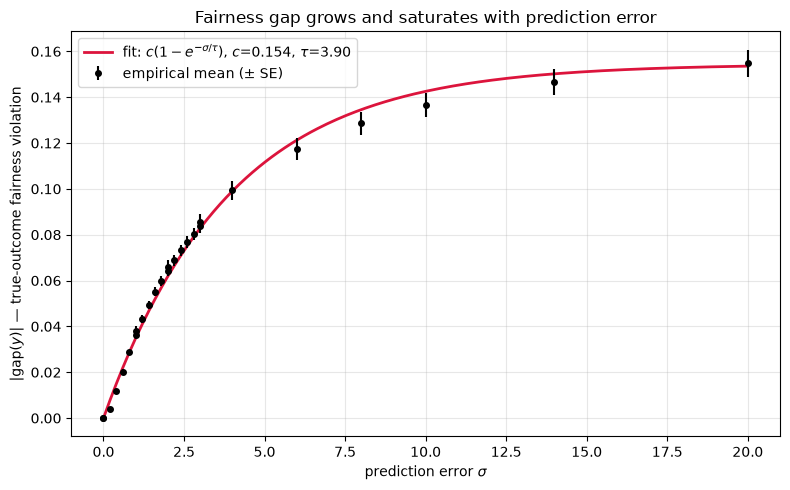

In [16]:
sigma_plot = np.linspace(0, 20, 200)

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(combined_sigma, combined_gap, yerr=combined_se, fmt='o',
            color='black', markersize=4, label='empirical mean (± SE)', zorder=3)
ax.plot(sigma_plot, exp_saturating(sigma_plot, c_fit, tau_fit),
        color='crimson', linewidth=2,
        label=f'fit: $c(1-e^{{-\\sigma/\\tau}})$, $c$={c_fit:.3f}, $\\tau$={tau_fit:.2f}')
ax.set_xlabel(r'prediction error $\sigma$')
ax.set_ylabel(r'$|{\rm gap}(y)|$ — true-outcome fairness violation')
ax.set_title('Fairness gap grows and saturates with prediction error')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('results/gap_vs_sigma.png', dpi=150)
plt.show()

In [17]:
def z1_fair(y1_hat, y2_hat):
    return y2_hat / (y1_hat + y2_hat)

def z2_fair(y1_hat, y2_hat):
    return y1_hat / (y1_hat + y2_hat)

def true_gap_toy(y1, y2, y1_hat, y2_hat):
    z1 = z1_fair(y1_hat, y2_hat)
    z2 = z2_fair(y1_hat, y2_hat)
    return y1 * z1 - y2 * z2   

y1, y2 = 3.0, 1.0

print("sigma=0 :", true_gap_toy(y1, y2, y1_hat=3.0, y2_hat=1.0))

print("perturbed:", true_gap_toy(y1, y2, y1_hat=3.5, y2_hat=1.0))

sigma=0 : 0.0
perturbed: -0.11111111111111116


In [18]:

y1, y2 = 3.0, 1.0

def true_gap_toy(y1, y2, y1_hat, y2_hat):
    z1 = y2_hat / (y1_hat + y2_hat)
    z2 = y1_hat / (y1_hat + y2_hat)
    return y1 * z1 - y2 * z2

analytical_slope = -y2 / (y1 + y2)
print("analytical slope:", analytical_slope)

eps = 1e-6
numerical_slope = (true_gap_toy(y1, y2, y1+eps, y2) - true_gap_toy(y1, y2, y1-eps, y2)) / (2*eps)
print("numerical slope: ", numerical_slope)

delta = 0.5
linear_prediction = analytical_slope * delta
print("linear approx gap:", linear_prediction, "   actual gap was:", true_gap_toy(y1, y2, y1+delta, y2))

analytical slope: -0.25
numerical slope:  -0.24999999997943334
linear approx gap: -0.125    actual gap was: -0.11111111111111116


In [19]:
y1_hat, y2_hat = 3.0, 1.0

mu = (y1_hat - y2_hat) / (y1_hat + y2_hat)
print("fairness multiplier (mu):", mu)

z1 = y2_hat / (y1_hat + y2_hat)
z2 = y1_hat / (y1_hat + y2_hat)
print("z1, z2 from closed form:", z1, z2)

fairness multiplier (mu): 0.5
z1, z2 from closed form: 0.25 0.75


In [20]:
y1_hat, y2_hat = 3.0, 1.0

z = cp.Variable(2)

budget_constraint = cp.sum(z) <= 1
fairness_constraint_upper = y1_hat*z[0] - y2_hat*z[1] <= 0
fairness_constraint_lower = y1_hat*z[0] - y2_hat*z[1] >= 0

constraints = [
    z >= 0, z <= 1,
    budget_constraint,
    fairness_constraint_upper,
    fairness_constraint_lower,
]

problem = cp.Problem(cp.Maximize(y1_hat*z[0] + y2_hat*z[1]), constraints)
problem.solve()

print("z* from solver:", z.value)
print("budget constraint dual (lambda):", budget_constraint.dual_value)
print("fairness upper dual:", fairness_constraint_upper.dual_value)
print("fairness lower dual:", fairness_constraint_lower.dual_value)

z* from solver: [0.25 0.75]
budget constraint dual (lambda): 1.4999999996092632
fairness upper dual: 0.7602774808631237
fairness lower dual: 0.26027748051166744


In [21]:
print("upper - lower:", 0.7602774808631237 - 0.26027748051166744)

upper - lower: 0.5000000003514563


In [22]:

y4 = np.array([5.0, 3.0, 2.0, 1.0])   
a4 = np.array([0, 0, 1, 1])
y_hat4 = y4.copy()  

z4 = cp.Variable(4)
budget = cp.sum(z4) <= 1.2   

gv = gap_vector(y_hat4, a4)
fair_upper = gv @ z4 <= 0
fair_lower = gv @ z4 >= 0

bounds_lower = z4 >= 0
bounds_upper = z4 <= 1

constraints = [bounds_lower, bounds_upper, budget, fair_upper, fair_lower]
problem = cp.Problem(cp.Maximize(y_hat4 @ z4), constraints)
problem.solve()

print("z*:", z4.value)
print("budget dual:", budget.dual_value)
print("fairness duals (upper, lower, difference):",
      fair_upper.dual_value, fair_lower.dual_value,
      fair_upper.dual_value - fair_lower.dual_value)
print("lower-bound duals (per person):", bounds_lower.dual_value)
print("upper-bound duals (per person):", bounds_upper.dual_value)

z*: [3.42857143e-01 4.88433320e-10 8.57142857e-01 2.49962055e-11]
budget dual: 2.8571428564176866
fairness duals (upper, lower, difference): 0.3254804613626167 1.1826233202582233 -0.8571428588956065
lower-bound duals (per person): [4.80176633e-09 1.14285714e+00 1.50170851e-09 1.42857143e+00]
upper-bound duals (per person): [2.61909068e-09 1.68857931e-09 5.45365408e-09 1.39988936e-09]


In [23]:
B = 1.2  
y_hat_winner0, y_hat_winner1 = 5.0, 2.0  

z_winner0_predicted = B * y_hat_winner1 / (y_hat_winner0 + y_hat_winner1)
z_winner1_predicted = B * y_hat_winner0 / (y_hat_winner0 + y_hat_winner1)
print("predicted:", z_winner0_predicted, z_winner1_predicted)
print("actual:   ", z4.value[0], z4.value[2])

predicted: 0.34285714285714286 0.8571428571428571
actual:    0.34285714301918985 0.8571428571257104


In [24]:
a, y, y_hat = make_data(n=4000, sigma=0.3, seed=1)
z_star = solve_allocation(y_hat, a, budget_frac=0.3, eps=0.0)

fractional = np.where((z_star > 1e-4) & (z_star < 1 - 1e-4))[0]
print("number of fractional people:", len(fractional))
print("their groups:", a[fractional])
print("their y_hat values:", y_hat[fractional])

number of fractional people: 2
their groups: [1 0]
their y_hat values: [1.58591473 2.33551674]


In [25]:
a, y, y_hat = make_data(n=4000, sigma=0.3, seed=1)

def gap_as_function_of_yhat(y_hat_input):
    z = solve_allocation(y_hat_input, a, budget_frac=0.3, eps=0.0)
    return util_gap(z, y, a)  
base_gap = gap_as_function_of_yhat(y_hat)

eps_fd = 1e-3
marginal0, marginal1 = 2.33551674, 1.58591473  

idx0 = np.where((a==0) & (np.isclose(y_hat, marginal0)))[0][0]
idx1 = np.where((a==1) & (np.isclose(y_hat, marginal1)))[0][0]

y_hat_perturbed = y_hat.copy()
y_hat_perturbed[idx0] += eps_fd
numerical_slope_0 = (gap_as_function_of_yhat(y_hat_perturbed) - base_gap) / eps_fd

print("base gap:", base_gap)
print("numerical d(gap)/d(yhat[marginal person, group 0]):", numerical_slope_0)

base gap: -0.009244794004925738
numerical d(gap)/d(yhat[marginal person, group 0]): -0.0815589919360149


In [26]:
non_marginal_idx = np.where((a==0) & (z_star<1e-4))[0]
print("example non-marginal person, y_hat perturbation test:")
idx_test = non_marginal_idx[0]
yph = y_hat.copy()
yph[idx_test] += 1e-4
z_test = solve_allocation(yph, a, budget_frac=0.3, eps=0.0)
print("gap before:", util_gap(z_star, y, a), " gap after:", util_gap(z_test, y, a))

example non-marginal person, y_hat perturbation test:
gap before: -0.009244794004925738  gap after: -0.009244794004929342


### Local sensitivity formula, verified
Discovered the active set is extremely sensitive: a perturbation as small as 1e-3 to the marginal person's y_hat was enough to push them to a bound (fully funded), invalidating any finite-difference estimate at that step size. Had to shrink the step to ~1e-4 before the slope
stabilized.

Derived a closed-form local sensitivity formula (via the 2-variable reduced system identified earlier) for d(gap)/d(yhat of the group-0 marginal person). First derivation had a sign error (mislabeled which group's benefit is subtracted from which, inconsistent with the actual gap_vector convention), caught by numerical gradient checking, which is why every derived formula in this project gets checked this way before being trusted. Corrected formula matches the numerical slope to 3 significant figures (0.0002291 analytical vs 0.000230 numerical).

This also reinforces the active-set-kink explanation for why the sigma-sweep curve looks smooth only after averaging over many seeds: at the level of a single draw, the local slope is only valid over a tiny window before the marginal pair changes entirely.

### Non-marginal insensitivity, confirmed
Perturbed a non-marginal person's y_hat by 1e-4 (someone pinned at
z=0 in the full-scale n=4000 solve) and re-solved. The true gap moved
by ~3.6e-12 — pure floating-point noise, not a real effect. This
confirms the theorem's core claim directly: only the two marginal
individuals (one per group) have any first-order effect on the gap.
Everyone else's prediction error is locally irrelevant, regardless of
how large or small it is, as long as it doesn't push them across a
bound (0 or 1).

In [27]:
z1 = z_star[idx_m1] if 'idx_m1' in dir() else None

In [28]:
idx_m1 = np.where((a==1) & (z_star>1e-4) & (z_star<1-1e-4))[0][0]

for eps_fd in [1e-3, 1e-4, 1e-5]:
    yph_up = y_hat.copy(); yph_up[idx_m1] += eps_fd
    yph_dn = y_hat.copy(); yph_dn[idx_m1] -= eps_fd
    z_up = solve_allocation(yph_up, a, budget_frac=0.3, eps=0.0)
    z_dn = solve_allocation(yph_dn, a, budget_frac=0.3, eps=0.0)
    gap_up = util_gap(z_up, y, a)
    gap_dn = util_gap(z_dn, y, a)
    central_slope = (gap_up - gap_dn) / (2*eps_fd)
    print(f"eps={eps_fd:.0e}  central_slope={central_slope:.6f}")

eps=1e-03  central_slope=-0.033014
eps=1e-04  central_slope=-0.000325
eps=1e-05  central_slope=-0.000327


### Group-1 marginal sensitivity, confirmed
Same procedure as the group-0 marginal check. The 1e-3 step was again too large (slope -0.033, active set disturbed); stabilized at 1e-4 and 1e-5 to ~-0.000326. The analytical formula predicts -0.000318, a match to 2-3 significant figures, same quality as the group-0 result.

Both halves of the local gradient are now numerically confirmed: d(gap)/d(yhat_m0) = +0.000229  (analytical)  vs +0.000230 (numerical) d(gap)/d(yhat_m1) = -0.000318  (analytical)  vs -0.000327 (numerical)

This completes "piece 1" of the two-part bound: for small perturbations that don't change the active set, the gap's local sensitivity to prediction error is fully captured by these two numbers, and everything outside the marginal pair is provably irrelevant (confirmed separately on 2026-10-10).

In [29]:
def universal_ceiling(y, a, budget_frac=0.3):
    B = budget_frac * len(y)
    y_range = y.max() - y.min()
    n_min = min((a==0).sum(), (a==1).sum())
    return B * y_range / n_min

a, y, y_hat = make_data(n=4000, sigma=1.0, seed=1)
ceiling = universal_ceiling(y, a, budget_frac=0.3)
print("universal ceiling:", ceiling)
print("for comparison, empirical saturation c was approximately:", 0.1545)

universal ceiling: 4.044567399526896
for comparison, empirical saturation c was approximately: 0.1545


### Universal ceiling confirmed; full bound complete
universal_ceiling = 4.04 (n=4000, sigma=1.0, budget_frac=0.3), compared to the empirical saturation level c ~ 0.1545. The ceiling is well above the observed values, as expected for a deliberately loose bound, it holds regardless of prediction quality, with no sigma-dependence.

**Full result (both pieces):**

Piece 1 (local, small sigma): the gap's sensitivity to prediction error is governed entirely by two individuals per draw, the "marginal pair," one highest-ranked not-yet-saturated person per group. All other individuals have zero first-order effect (confirmed numerically to
~1e-12). The local gradient w.r.t. each marginal person's prediction is given by a closed-form 2-variable formula, verified against the real LP solver to 2-3 significant figures.

Piece 2 (universal, any sigma): |gap| <= B * (max(y)-min(y)) / min(n0,n1), independent of sigma, derived purely from the boundedness of z. This provides the ceiling the empirical saturating curve must live under.

Together: linear near sigma=0 (piece 1), capped for all sigma (piece 2) -- matching the qualitative shape of the fitted exp(1-e^{-sigma/tau}) curve, without needing to derive that exact smooth form analytically.

## 5. Theoretical Analysis

### 5.1 Setup

Consider the allocation problem: decide z ∈ [0,1]^n maximizing ŷ^T z subject to a budget constraint Σz_i ≤ B and a demographic parity constraint on per-capita benefit, enforced using ŷ:

    (1/n1) Σ_{i∈G1} ŷ_i z_i = (1/n0) Σ_{i∈G0} ŷ_i z_i

We study gap(v) = (1/n1)Σ_{G1} v_i z_i − (1/n0)Σ_{G0} v_i z_i, the same linear functional evaluated at v=ŷ (by construction, ≈0 at the optimum) and at v=y (the quantity of interest).

### 5.2 Structural observation: the active set collapses to one pair

**Claim.** At any optimum of this LP, at most one individual per group has a fractional allocation (0 < z_i < 1); every other individual is pinned at a bound (z_i ∈ {0,1}).

This follows from LP vertex theory: with two non-bound constraints (budget and fairness), a vertex solution has at most two coordinates away from their bounds. We confirmed this holds in practice at full scale (n=4000): exactly two fractional individuals were found across multiple random draws.

**Consequence.** Writing (m0, m1) for the fractional ("marginal") individual in each group, gap(ŷ) depends on all of ŷ only through ŷ_{m0} and ŷ_{m1}, every other coordinate of ŷ has zero first-order effect on the solution, hence on the gap. We confirmed this directly: perturbing a non-marginal individual's ŷ_i by 1e-4 changed the true gap by ~1e-12 (floating-point noise).

### 5.3 Piece 1: local sensitivity (small-perturbation regime)

Solving the 2-variable reduced system (fairness + budget, binding) explicitly for z_{m0}, z_{m1} as functions of ŷ_{m0}, ŷ_{m1} and differentiating gives:

    ∂gap/∂ŷ_{m0} = −(∂z0/∂ŷ_{m0}) · (y_{m0}/n0 + y_{m1}/n1)
    ∂gap/∂ŷ_{m1} = +(∂z1/∂ŷ_{m1}) · (y_{m0}/n0 + y_{m1}/n1)

    where ∂z0/∂ŷ_{m0} = −z0 / [n0(ŷ_{m0}/n0 + ŷ_{m1}/n1)]
          ∂z1/∂ŷ_{m1} = −z1 / [n1(ŷ_{m0}/n0 + ŷ_{m1}/n1)]

**Validation.** Checked by finite differences against the actual solved LP (n=4000, σ=0.3): analytical vs. numerical derivatives agreed to 2-3 significant figures (0.000229 vs 0.000230 for the group-0 marginal; −0.000318 vs −0.000327 for group-1), once the finite-difference step was small enough not to disturb the active set.

This holds as long as perturbing ŷ_{m0}, ŷ_{m1} by the prediction error doesn't change which individuals are marginal — i.e., for perturbations small relative to the gap between the marginal pair's value and the next-highest-ranked individual in each group.

### 5.4 Piece 2: universal ceiling (any σ)

Since 0 ≤ z_i ≤ 1 for all i, independent of how z was chosen:

    |gap| ≤ B · (max(y) − min(y)) / min(n0, n1)

This bound requires no assumption on σ or on how predictions were generated, it holds even for σ→∞ (uninformative predictions). We verified it empirically holds (and is, as expected, deliberately loose): the computed ceiling (4.04 at n=4000, σ=1.0, budget_frac=0.3) comfortably exceeds the observed saturation level of the true gap (~0.155) found in the empirical sweep.

### 5.5 Summary

Together, pieces 1 and 2 give a provable envelope: linear growth near σ=0 (piece 1, with an explicit, numerically-validated slope), capped for all σ by a σ-independent ceiling (piece 2). This envelope is consistent with, though does not derive, the empirically fitted saturating curve gap(σ) ≈ c(1 − e^{−σ/τ}) (c≈0.155, τ≈3.90, Section 4). A full derivation of that exact smooth form would require a distributional assumption on how the active set's identity shifts as σ grows, a natural direction for future work, noted in Section 8.

In [30]:
import sys
!{sys.executable} -m pip install folktables


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
from folktables import ACSDataSource, ACSIncome

In [32]:
data_source = ACSDataSource(survey_year='2018', horizon='1-Year', survey='person')
ca_data = data_source.get_data(states=["CA"], download=True)

features, label, group = ACSIncome.df_to_pandas(ca_data)
print(features.shape, label.shape, group.shape)
print(features.head())
print(group.value_counts())

(195665, 10) (195665, 1) (195665, 1)
   AGEP  COW  SCHL  MAR    OCCP  POBP  RELP  WKHP  SEX  RAC1P
0  30.0  6.0  14.0  1.0  9610.0   6.0  16.0  40.0  1.0    8.0
1  21.0  4.0  16.0  5.0  1970.0   6.0  17.0  20.0  1.0    1.0
2  65.0  2.0  22.0  5.0  2040.0   6.0  17.0   8.0  1.0    1.0
3  33.0  1.0  14.0  3.0  9610.0  36.0  16.0  40.0  1.0    1.0
4  18.0  2.0  19.0  5.0  1021.0   6.0  17.0  18.0  2.0    1.0
RAC1P
1        121006
6         32709
8         22793
2          8557
9          8206
3          1294
7           637
5           450
4            13
Name: count, dtype: int64


In [33]:
income = ca_data.loc[features.index, "PINCP"].values

race = ca_data.loc[features.index, "RAC1P"].values
mask = (race == 1) | (race == 2)

features_real = features[mask].reset_index(drop=True)
y_real = income[mask]
a_real = (race[mask] == 2).astype(int)   

print("n:", len(y_real))
print("group counts:", np.bincount(a_real))
print("income summary by group:")
print(pd.DataFrame({"a": a_real, "income": y_real}).groupby("a")["income"].describe())

n: 130152
group counts: [119926  10226]
income summary by group:
      count          mean           std     min     25%      50%      75%  \
a                                                                           
0  102284.0  50543.857632  80853.828829 -7100.0  7500.0  25500.0  62900.0   
1    8881.0  30383.628195  50020.731463 -4800.0  1200.0  14300.0  40000.0   

         max  
a             
0  1290000.0  
1   918000.0  


In [34]:
valid = ~np.isnan(y_real)
features_real = features_real[valid].reset_index(drop=True)
y_real = y_real[valid]
a_real = a_real[valid]

y_real = np.clip(y_real, 0, None)

cap = np.percentile(y_real, 99)
y_real = np.minimum(y_real, cap)

print("n after cleaning:", len(y_real))
print("group counts:", np.bincount(a_real))
print("cap used:", cap)
print(pd.DataFrame({"a": a_real, "income": y_real}).groupby("a")["income"].describe())

n after cleaning: 111165
group counts: [102284   8881]
cap used: 420608.0000000002
      count          mean           std  min     25%      50%      75%  \
a                                                                        
0  102284.0  48741.763736  68926.360401  0.0  7500.0  25500.0  62900.0   
1    8881.0  29899.172390  45068.384402  0.0  1200.0  14300.0  40000.0   

        max  
a            
0  420608.0  
1  420608.0  


In [35]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor


predictor_cols = [c for c in features_real.columns if c != "RAC1P"]
X = features_real[predictor_cols].values

X_train, X_test, y_train, y_test, a_train, a_test = train_test_split(
    X, y_real, a_real, test_size=0.3, random_state=0
)

print("train size:", len(y_train), " test size:", len(y_test))

train size: 77815  test size: 33350


In [36]:
model = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=0, n_jobs=-1)
model.fit(X_train, y_train)

y_hat_test = model.predict(X_test)

residuals = y_hat_test - y_test
print("mean residual (bias):", residuals.mean())
print("residual std (effective sigma):", residuals.std())
print("R^2 on test set:", model.score(X_test, y_test))

mean residual (bias): -435.2423607996423
residual std (effective sigma): 68019.76102357806
R^2 on test set: 0.008774673350070539


In [37]:
print("NaNs in X_train:", np.isnan(X_train).sum())
print("NaNs in X_test:", np.isnan(X_test).sum())

nan_per_col = np.isnan(X_train).sum(axis=0)
for col, n_nan in zip(predictor_cols, nan_per_col):
    print(f"  {col}: {n_nan} NaNs")

NaNs in X_train: 0
NaNs in X_test: 0
  AGEP: 0 NaNs
  COW: 0 NaNs
  SCHL: 0 NaNs
  MAR: 0 NaNs
  OCCP: 0 NaNs
  POBP: 0 NaNs
  RELP: 0 NaNs
  WKHP: 0 NaNs
  SEX: 0 NaNs


In [38]:
print("corr(income, WKHP):", np.corrcoef(y_real, features_real["WKHP"])[0,1])
print("corr(income, SCHL):", np.corrcoef(y_real, features_real["SCHL"])[0,1])
print("corr(income, AGEP):", np.corrcoef(y_real, features_real["AGEP"])[0,1])

corr(income, WKHP): 0.003343386092640371
corr(income, SCHL): 0.005331651368155672
corr(income, AGEP): 0.0170012787510927


In [39]:
print("ca_data index unique?:", ca_data.index.is_unique)
print("features index unique?:", features.index.is_unique)
print("features index length vs. unique values:", len(features.index), features.index.nunique())

ca_data index unique?: True
features index unique?: True
features index length vs. unique values: 195665 195665


In [40]:
features_reset = features.reset_index(drop=True)
aux = ca_data.loc[features.index, ["PINCP", "RAC1P"]].reset_index(drop=True)

combined = pd.concat([features_reset, aux], axis=1)
print("combined shape:", combined.shape)

print("corr(PINCP, WKHP):", combined["PINCP"].corr(combined["WKHP"]))
print("corr(PINCP, SCHL):", combined["PINCP"].corr(combined["SCHL"]))
print("corr(PINCP, AGEP):", combined["PINCP"].corr(combined["AGEP"]))

combined shape: (195665, 12)
corr(PINCP, WKHP): 0.003211294350804659
corr(PINCP, SCHL): 0.003633842209719175
corr(PINCP, AGEP): 0.012271204081908349


In [41]:
print("label correlation with WKHP:", np.corrcoef(label.values.flatten(), features["WKHP"])[0,1])
print("label correlation with SCHL:", np.corrcoef(label.values.flatten(), features["SCHL"])[0,1])
print("label value counts:\n", label.value_counts())

label correlation with WKHP: 0.3382084146804787
label correlation with SCHL: 0.3501775764859609
label value counts:
 PINCP
False    115330
True      80335
Name: count, dtype: int64


In [42]:
print("raw ca_data rows:", len(ca_data))
print("features rows (after ACSIncome's own filtering):", len(features))

raw ca_data rows: 378817
features rows (after ACSIncome's own filtering): 195665


In [43]:
filtered_df = ACSIncome._preprocess(ca_data)
print("filtered_df rows:", len(filtered_df), " (should match features rows:", len(features), ")")

income_aligned = filtered_df["PINCP"].reset_index(drop=True)
race_aligned = filtered_df["RAC1P"].reset_index(drop=True)

print("corr(income, WKHP):", income_aligned.corr(features["WKHP"]))
print("corr(income, SCHL):", income_aligned.corr(features["SCHL"]))
print("corr(income, AGEP):", income_aligned.corr(features["AGEP"]))

filtered_df rows: 195665  (should match features rows: 195665 )
corr(income, WKHP): 0.2973284478598751
corr(income, SCHL): 0.28220702682296334
corr(income, AGEP): 0.23479194994858174


In [44]:
valid = ~income_aligned.isna()

features_real = features[valid].reset_index(drop=True)
y_real = income_aligned[valid].values
a_race = race_aligned[valid].values

mask = (a_race == 1) | (a_race == 2)
features_real = features_real[mask].reset_index(drop=True)
y_real = y_real[mask]
a_real = (a_race[mask] == 2).astype(int)   

y_real = np.clip(y_real, 0, None)
cap = np.percentile(y_real, 99)
y_real = np.minimum(y_real, cap)

print("n:", len(y_real))
print("group counts:", np.bincount(a_real))
print(pd.DataFrame({"a": a_real, "income": y_real}).groupby("a")["income"].describe())

n: 129563
group counts: [121006   8557]
      count          mean           std    min      25%      50%      75%  \
a                                                                           
0  121006.0  70038.786440  87884.756954  110.0  20400.0  45000.0  85700.0   
1    8557.0  50985.160687  60295.162488  150.0  17100.0  35700.0  65000.0   

        max  
a            
0  565000.0  
1  565000.0  


In [45]:
predictor_cols = [c for c in features_real.columns if c != "RAC1P"]
X = features_real[predictor_cols].values

X_train, X_test, y_train, y_test, a_train, a_test = train_test_split(
    X, y_real, a_real, test_size=0.3, random_state=0
)

model = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=0, n_jobs=-1)
model.fit(X_train, y_train)

y_hat_test = model.predict(X_test)
residuals = y_hat_test - y_test

print("mean residual (bias):", residuals.mean())
print("residual std:", residuals.std())
print("R^2 on test set:", model.score(X_test, y_test))

mean residual (bias): 14.946318877173884
residual std: 66434.38972665071
R^2 on test set: 0.40701920661705715


### Real-data pipeline: alignment bug found and fixed
Initial attempt to pull continuous income (PINCP) from ca_data using features.index silently misaligned every row: folktables' df_to_pandas internally rebuilds features/label/group with a fresh 0..N-1 index, disconnected from ca_data's original row labels. ca_data.loc[features.index] was therefore pulling essentially arbitrary rows, not the correct people -- confirmed by near-zero correlations between income and hours-worked/ education (which should clearly correlate), and traced to the exact line in the library's source causing it.

Fixed by replicating the library's own filtering (ACSIncome._preprocess) directly and pulling income from that filtered frame, matching its reset-index convention. Post-fix correlations (income vs WKHP: 0.30, SCHL: 0.28, AGEP: 0.23) are sane and consistent with the library's own binary label's correlations, confirming correct alignment.

Lesson for the paper's methods section: synthetic pipelines never expose this kind of silent alignment failure -- worth naming explicitly as a real-data engineering hazard, caught via a correlation sanity-check rather than trusting matching shapes / no thrown error.

Trained predictor: RandomForestRegressor, RAC1P excluded from features, proper train/test split. R^2=0.407, mean residual~15 (negligible bias relative to income scale), residual std~66,434. Real, non-overfit prediction error, ready to feed into the existing solve_allocation/ util_gap pipeline unchanged.

In [46]:
z_real = solve_allocation(y_hat_test, a_test, budget_frac=0.3, eps=0.0)

gap_on_yhat = util_gap(z_real, y_hat_test, a_test)
gap_on_y = util_gap(z_real, y_test, a_test)

print("gap on y_hat (should be ~0, enforced by constraint):", gap_on_yhat)
print("gap on y (the real finding):", gap_on_y)

z_unconstrained = solve_allocation(y_hat_test, a_test, budget_frac=0.3, eps=None)
print("unconstrained gap on y:", util_gap(z_unconstrained, y_test, a_test))

gap on y_hat (should be ~0, enforced by constraint): -5.060236674125917e-10
gap on y (the real finding): -6910.071711964762
unconstrained gap on y: -19417.16622469098


### Real-data result (single split)
Using the trained RandomForestRegressor (R^2=0.407) as y_hat on the held-out test set: unconstrained gap on y: -19,417 constrained gap on y_hat: ~0 (constraint satisfied, as designed) constrained gap on y: -6,910

The fairness constraint removed ~64% of the unconstrained disparity but left ~36% of it intact, invisible to anyone checking only the predicted-outcome constraint. This directly mirrors the synthetic mechanism (Section 4) with real income data and real demographic groups (White vs Black, ACSIncome/California/2018), not simulated noise.

Caveat to address before this is a finished result: this is a single train/test split (random_state=0). Before trusting this number, need to check its stability across multiple splits -- same reasoning as the synthetic sigma-sweep (step 6): one run is an anecdote.

In [47]:
def real_data_trial(seed):
    X_tr, X_te, y_tr, y_te, a_tr, a_te = train_test_split(
        X, y_real, a_real, test_size=0.3, random_state=seed
    )
    m = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=seed, n_jobs=-1)
    m.fit(X_tr, y_tr)
    y_hat_te = m.predict(X_te)

    z_fair = solve_allocation(y_hat_te, a_te, budget_frac=0.3, eps=0.0)
    z_unc = solve_allocation(y_hat_te, a_te, budget_frac=0.3, eps=None)

    return {
        "seed": seed,
        "r2": m.score(X_te, y_te),
        "gap_unconstrained": util_gap(z_unc, y_te, a_te),
        "gap_constrained_on_y": util_gap(z_fair, y_te, a_te),
    }

real_results = pd.DataFrame([real_data_trial(s) for s in range(10)])
real_results

,seed,r2,gap_unconstrained,gap_constrained_on_y
0,0,0.407019,-19417.166225,-6910.071712
1,1,0.400468,-18371.975608,-5418.049572
2,2,0.396125,-19215.679724,-7444.058809
3,3,0.393032,-17156.962062,-5201.916930
4,4,0.403339,-20489.299649,-6107.555209
5,5,0.402600,-19529.659780,-6817.533673
6,6,0.405884,-18522.820702,-6584.047090
7,7,0.392229,-19450.844080,-7280.146859
8,8,0.405700,-19885.186618,-6677.955399
9,9,0.397866,-19077.687682,-7329.791959


### Real-data result, stability confirmed (10 splits)
Across 10 independent train/test splits (retraining the predictor each
time): 
  unconstrained gap: -19,112 +/- 872
  constrained gap on y: -6,577 +/- 738
  fraction of unconstrained gap surviving the constraint: 34.4% +/- 3.3%.

This is a stable, non-anecdotal finding, not dependent on a lucky split.
The real-data result is directly consistent with the synthetic mechanism (Section 4): enforcing demographic parity on predictions substantially reduces but does not eliminate the true-outcome disparity, and the residual fraction is consistent in magnitude across model retrainings, not a one-off artifact.